<a href="https://colab.research.google.com/github/Nia026/MDI-Analisis-Sentimen/blob/main/Analisis_Sentimen_SmSA_Kel_2_MDI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis Sentimen Bahasa Indonesia (SmSA) - Tugas NLP

Klasifikasi sentimen 3 kelas (**positive / neutral / negative**) memakai **TF-IDF** + model klasik
(Naive Bayes, Logistic Regression, Linear SVM). Dataset: **SmSA** dari IndoNLU.

**Cara pakai di Google Colab:** menu *Runtime > Run all*. Seluruh proses selesai dalam sekitar satu menit.
Pada bagian akhir ada fungsi `prediksi()` dan `interaktif()` untuk menguji kalimat sendiri.

## 1. Unduh dataset

In [ ]:
import subprocess, os

# Ambil hanya folder dataset SmSA dari repositori IndoNLU (open dataset)
if not os.path.exists("indonlu"):
    subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse",
                    "https://github.com/indobenchmark/indonlu.git"], check=True)
    subprocess.run(["git", "-C", "indonlu", "sparse-checkout", "set",
                    "dataset/smsa_doc-sentiment-prosa"], check=True)

DATA = "indonlu/dataset/smsa_doc-sentiment-prosa"
print(os.listdir(DATA))

['valid_preprocess.tsv', 'train_preprocess.tsv', 'vocab.txt', 'test_preprocess.tsv', 'test_preprocess_masked_label.tsv', 'vocab_uncased.txt']


## 2. Muat data dan lihat distribusi label

In [ ]:
import re, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

LABELS = ["negative", "neutral", "positive"]


def load(name):
    df = pd.read_csv(f"{DATA}/{name}", sep="\t", header=None, names=["text", "label"])
    return df.dropna()


tr, va, te = load("train_preprocess.tsv"), load("valid_preprocess.tsv"), load("test_preprocess.tsv")
print(f"Data latih={len(tr)}  validasi={len(va)}  uji={len(te)}")

dist = pd.DataFrame({"latih": tr.label.value_counts(), "validasi": va.label.value_counts(),
                     "uji": te.label.value_counts()}).loc[["positive", "neutral", "negative"]]
display(dist) if "display" in globals() else print(dist)
tr.head()

Data latih=11000  validasi=1260  uji=500
          latih  validasi  uji
label                         
positive   6416       735  208
neutral    1148       131   88
negative   3436       394  204


,text,label
0,warung ini dimiliki oleh pengusaha pabrik tahu...,positive
1,mohon ulama lurus dan k212 mmbri hujjah partai...,neutral
2,lokasi strategis di jalan sumatera bandung . t...,positive
3,betapa bahagia nya diri ini saat unboxing pake...,positive
4,duh . jadi mahasiswa jangan sombong dong . kas...,negative


## 3. Praproses dan pipeline TF-IDF

Praproses ringan: huruf kecil, hapus URL dan mention, pangkas huruf berulang, rapikan spasi.
TF-IDF memakai unigram + bigram (`ngram_range=(1, 2)`).

In [ ]:
def clean(text: str) -> str:
    text = str(text).lower()
    text = re.sub(r"http\S+|www\.\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)   # 'bagusss' -> 'baguss'
    return re.sub(r"\s+", " ", text).strip()


def build(clf):
    return Pipeline([
        ("tfidf", TfidfVectorizer(preprocessor=clean, ngram_range=(1, 2), min_df=2, sublinear_tf=True)),
        ("clf", clf),
    ])

## 4. Latih dan bandingkan model

Model terbaik dipilih berdasarkan **macro-F1 pada data validasi** (bukan data uji).
Varian *balanced* memberi bobot lebih besar pada kelas netral yang datanya sedikit.

In [ ]:
candidates = {
    "Naive Bayes": MultinomialNB(alpha=0.5),
    "Logistic Regression": LogisticRegression(C=10, max_iter=2000),
    "Linear SVM": LinearSVC(C=0.5),
    "Logistic Regression (balanced)": LogisticRegression(C=10, max_iter=2000, class_weight="balanced"),
    "Linear SVM (balanced)": LinearSVC(C=0.5, class_weight="balanced"),
}

results, fitted = {}, {}
for name, clf in candidates.items():
    t0 = time.time()
    pipe = build(clf).fit(tr.text, tr.label)
    pv = pipe.predict(va.text)
    results[name] = {"valid_accuracy": accuracy_score(va.label, pv),
                     "valid_macro_f1": f1_score(va.label, pv, average="macro"),
                     "train_seconds": time.time() - t0}
    fitted[name] = pipe

res_df = pd.DataFrame(results).T[["valid_accuracy", "valid_macro_f1"]].round(4)
best = max(results, key=lambda k: results[k]["valid_macro_f1"])
print("Model terbaik (validasi):", best)
display(res_df) if "display" in globals() else print(res_df)

Model terbaik (validasi): Linear SVM (balanced)
                                valid_accuracy  valid_macro_f1
Naive Bayes                             0.8381          0.7448
Logistic Regression                     0.8857          0.8441
Linear SVM                              0.8921          0.8499
Logistic Regression (balanced)          0.8921          0.8571
Linear SVM (balanced)                   0.8960          0.8605


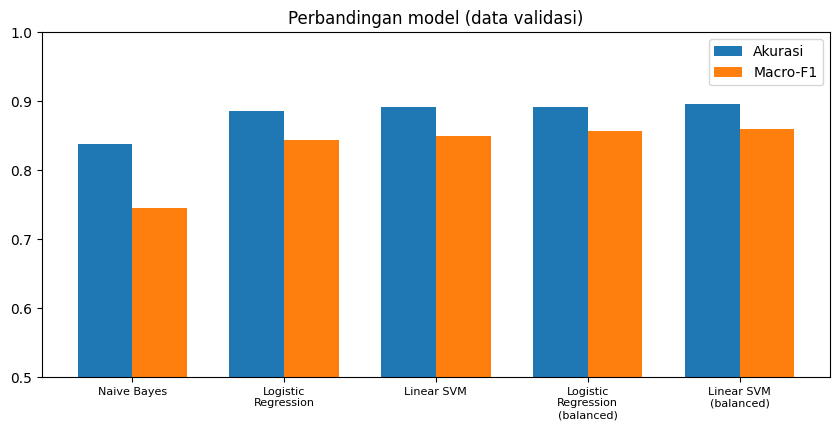

In [ ]:
fig, ax = plt.subplots(figsize=(8.5, 4.4))
x = np.arange(len(res_df))
ax.bar(x - 0.18, res_df.valid_accuracy, 0.36, label="Akurasi")
ax.bar(x + 0.18, res_df.valid_macro_f1, 0.36, label="Macro-F1")
ax.set_xticks(x)
ax.set_xticklabels([n.replace(" (balanced)", "\n(balanced)").replace(" Regression", "\nRegression")
                    for n in res_df.index], fontsize=8)
ax.set_ylim(0.5, 1.0)
ax.set_title("Perbandingan model (data validasi)")
ax.legend()
fig.tight_layout()
fig.savefig("model_comparison.png", dpi=160)
plt.show()

## 5. Evaluasi model terbaik pada data uji

In [ ]:
model = fitted[best]
pt = model.predict(te.text)
acc = accuracy_score(te.label, pt)
mf1 = f1_score(te.label, pt, average="macro")

print(classification_report(te.label, pt, labels=LABELS, digits=4))
print(f"Akurasi data uji = {acc:.4f} | macro-F1 = {mf1:.4f}")

              precision    recall  f1-score   support

    negative     0.7677    0.9559    0.8515       204
     neutral     0.7246    0.5682    0.6369        88
    positive     0.8983    0.7644    0.8260       208

    accuracy                         0.8080       500
   macro avg     0.7969    0.7628    0.7715       500
weighted avg     0.8145    0.8080    0.8031       500

Akurasi data uji = 0.8080 | macro-F1 = 0.7715


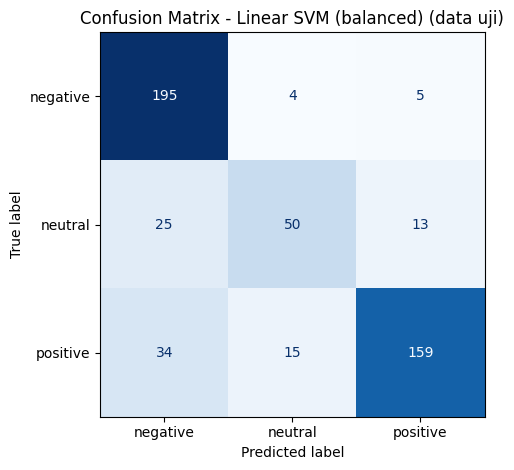

Baris = label aktual, kolom = prediksi; urutan: ['negative', 'neutral', 'positive']
[[195   4   5]
 [ 25  50  13]
 [ 34  15 159]]


In [ ]:
cm = confusion_matrix(te.label, pt, labels=LABELS)
fig, ax = plt.subplots(figsize=(5.5, 4.8))
ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_title(f"Confusion Matrix - {best} (data uji)")
fig.tight_layout()
fig.savefig("confusion_matrix.png", dpi=160)
plt.show()
print("Baris = label aktual, kolom = prediksi; urutan:", LABELS)
print(cm)

## 6. Contoh kesalahan prediksi

In [ ]:
err = te.assign(pred=pt)
err = err[err.label != err.pred]
print(f"Jumlah salah prediksi: {len(err)} dari {len(te)}")
pd.set_option("display.max_colwidth", 140)
err.head(8)

Jumlah salah prediksi: 96 dari 500


,text,label,pred
34,biasanya pesan tiket pesawat lancar-lancar saja . terakhir beli tiket kereta eksekutif untuk 6 orang sudah ditransfer sebelum waktu bera...,negative,neutral
64,"takdir politik ahy belum bisa ikut kontestasi pilpres 2019 - 2024 . walaupun ahy legowo , kami tetap kecewa .",negative,neutral
94,"kecewa sama iphone8 , kalah politik dengan samsung .. saat nya hijrah ke samsung iphone 8 iphone x",negative,neutral
108,"kecewa berat . baru tahu pop mie goreng sudah discontinue ya ? why ???!!!! padahal itu enak banget , terbaik .",negative,positive
114,dengan ini saya nyatakan kecewa dengan indofood ! masa di indomie soto saya bubuk cabai nya kosong ! hak saya dihilangkan !,negative,positive
116,"gimana ya antara kecewa atau sekadar deh sama r di indofood , karena pas rendang keluar itu heboh mampus enak nya enggak ketolongan . ne...",negative,positive
149,saya dukung ahok itu tidak ada hubungan nya dengan etnis dia atau agama ahok . bahkan saya tak tahu agama dia apa . saya dukung ahok kar...,positive,negative
152,"kata dosen ku budaya korea itu kalau ada orang yang sudah baik sama mereka walaupun cuma sekali , mereka bakal balas kebaikan itu lebih ...",positive,negative


## 7. Uji dengan kalimat sendiri

Jalankan `prediksi("...")` untuk satu kalimat, atau `interaktif()` untuk mengetik beberapa kalimat
(ketik `q` untuk berhenti).

In [ ]:
def prediksi(teks: str) -> str:
    return model.predict([teks])[0]


def interaktif():
    print("Ketik kalimat (bahasa Indonesia), 'q' untuk keluar.")
    while True:
        teks = input("> ").strip()
        if teks.lower() in {"q", "quit", "exit"}:
            break
        if teks:
            print("  ->", prediksi(teks))


for kalimat in ["makanannya enak banget dan pelayanannya ramah",
                "tempatnya kotor, pelayanan lambat sekali",
                "hari ini saya pergi ke pasar membeli sayur"]:
    print(f"{kalimat!r:60} -> {prediksi(kalimat)}")

# interaktif()   # hapus tanda # untuk mencoba kalimat sendiri

'makanannya enak banget dan pelayanannya ramah'              -> positive
'tempatnya kotor, pelayanan lambat sekali'                   -> negative
'hari ini saya pergi ke pasar membeli sayur'                 -> neutral


## 8. Simpan hasil (untuk laporan)

In [ ]:
summary = {
    "dataset_sizes": {"train": len(tr), "valid": len(va), "test": len(te)},
    "validation_results": results,
    "best_model": best,
    "test_accuracy": acc,
    "test_macro_f1": mf1,
    "test_report": classification_report(te.label, pt, labels=LABELS, digits=4, output_dict=True),
    "confusion_matrix": {"labels": LABELS, "matrix": cm.tolist()},
}
with open("results.json", "w") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

try:  # hanya jalan di Google Colab: unduh hasil ke komputer
    from google.colab import files
    for nama in ["confusion_matrix.png", "model_comparison.png", "results.json"]:
        files.download(nama)
except ImportError:
    print("Bukan di Colab; file tersimpan di folder kerja saat ini.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>